# Phase 2: forward-only motif search at four levels

This notebook searches the 10-hour recording `SOCAL_H_76_230426_193500_df100.x.x.wav` for repeated motifs at the
four levels of humpback song (**unit, phrase, theme, song**), using the motif length ranges found in Phase 1
([`Whale_Song_Length_Range_Experiment.ipynb`](Whale_Song_Length_Range_Experiment.ipynb), saved in
`whale_length_ranges.json`). The 37.5-minute recording, which lies inside the 10-hour one, is searched
independently as a cross-check. The plan is in [`Length_Range_and_Forward_Search_Plan.md`](Length_Range_and_Forward_Search_Plan.md).

**Forward-only rule.** For each level, a window of length $W = 15 \times$ (longest motif length), capped at the
recording, starts at a lower bound `lb`:

1. Find the best repeated pair inside `[lb, lb + W)` over 5 log-spaced lengths of the level's range
   (`stumpy.stump`, exclusion zone = the full length, so the two occurrences never overlap).
2. If its correlation reaches the threshold, it is a **detection**: both occurrences are **blanked** (set to NaN, so
   no later window can use them) and `lb` moves to the **end of the earlier occurrence**. The search only ever looks
   forward.
3. Otherwise the candidate is logged as **rejected** and `lb` moves by the shortest length.

**Ranking and threshold.** Shorter windows always correlate better, so candidates of different lengths are ranked
by their *excess* correlation over the Phase 1 null at their own length (`r - null top-decile r(L)`), and a
detection must reach that null level. A run of rejections is skipped in one step when a window twice as long has no
pair above the threshold (every window inside it would be rejected too; such rows have `skipped > 1`). This leaves
the detections unchanged.

Everything is computed with helpers from [`whale_mfcc.py`](whale_mfcc.py) and cached as
`whale_forward_<level>_<feature>_<file>.csv`; the first run takes about 2 hours (mostly the unit level).

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle

import whale_mfcc as w

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 160)

LEVELS = ["unit", "phrase", "theme", "song"]
FEATURES = ["c0", "c1"]
COLORS = dict(unit="C0", phrase="C1", theme="C2", song="C3")
N_LENGTHS = 5

with open("whale_length_ranges.json") as f:
    RANGES = json.load(f)
FRAME_RATE = RANGES["meta"]["frame_rate"]
OFFSET_MIN = RANGES["meta"]["offset_014845_sec"] / 60
C10, _ = w.load_or_compute_features(w.WAV_10H_PATH, "whale_mfcc_193500_100hz.npz")
C37, _ = w.load_or_compute_features(w.WAV_PATH, "whale_mfcc_014845_100hz.npz")
DURATION_MIN = {"10h": len(C10) / FRAME_RATE / 60, "37min": len(C37) / FRAME_RATE / 60}
print(f"10 h file: {DURATION_MIN['10h'] / 60:.2f} h; 37.5 min file: {DURATION_MIN['37min']:.2f} min, "
      f"starting {OFFSET_MIN:.2f} min into the 10 h file")

10 h file: 10.00 h; 37.5 min file: 37.50 min, starting 373.74 min into the 10 h file


## Settings from Phase 1

`source` is the Phase 1 criterion that set the range (`excess`: half-maximum of the excess over the null; `bump`:
detrended-correlation bump; `regularity`: copies recurring once per song cycle).

In [2]:
def thresholds(feature, level):
    scan = pd.read_csv(f"whale_scan_{level}_{feature}.csv")
    return w.null_threshold(scan)


rows = []
for feature in FEATURES:
    for level in LEVELS:
        cfg = RANGES[feature][level]
        thr = thresholds(feature, level)
        lengths = np.unique(np.round(np.geomspace(cfg["lo_s"], cfg["hi_s"], N_LENGTHS) * cfg["rate_hz"])) / cfg["rate_hz"]
        rows.append({
            "feature": feature, "level": level, "range (s)": f"{cfg['lo_s']:.3g}-{cfg['hi_s']:.3g}",
            "source": cfg["source"], "rate (Hz)": cfg["rate_hz"],
            "window W (min)": round(min(15 * cfg["hi_s"] / 60, DURATION_MIN["10h"]), 2),
            "lengths (s)": ", ".join(f"{x:.3g}" for x in lengths),
            "threshold r": ", ".join(f"{thr(x):.2f}" for x in lengths),
        })
pd.DataFrame(rows).set_index(["feature", "level"])

range (s)      source  rate (Hz)  window W (min)                   lengths (s)                   threshold r
feature level                                                                                                               
c0      unit    1.73-4.15        bump        100            1.04  1.73, 2.15, 2.68, 3.33, 4.15  0.92, 0.90, 0.89, 0.87, 0.85
        phrase    8.9-120      excess         10           30.00    8.9, 17.1, 32.7, 62.6, 120  0.77, 0.64, 0.51, 0.43, 0.39
        theme     75.5-95        bump          2           23.75      75.5, 80, 84.5, 89.5, 95  0.54, 0.54, 0.53, 0.53, 0.53
        song      420-540  regularity          1          135.00       420, 447, 476, 507, 540  0.70, 0.70, 0.71, 0.71, 0.70
c1      unit    2.68-5.16        bump        100            1.29  2.68, 3.16, 3.72, 4.38, 5.16  0.82, 0.81, 0.80, 0.79, 0.78
        phrase    8.9-120      excess         10           30.00    8.9, 17.1, 32.7, 62.6, 120  0.78, 0.68, 0.57, 0.47, 0.38
        theme      60-302      excess          2           75.62         60, 90, 134, 202, 302  0.65, 0.58, 0.53, 0.52, 0.52
        song      300-600  regularity          1          150.00       300, 357, 424, 505, 600  0.59, 0.58, 0.59, 0.58, 0.57

## Run the search

Both features, all four levels, on both recordings (cached; delete a CSV to recompute it).

In [3]:
RESULTS = {}
for tag, C in (("10h", C10), ("37min", C37)):
    for level in LEVELS:
        for feature in FEATURES:
            df = w.forward_level(C, FRAME_RATE, RANGES, feature, level, tag, n_lengths=N_LENGTHS)
            RESULTS[tag, feature, level] = df.assign(file=tag)
ALL = pd.concat(RESULTS.values(), ignore_index=True)
ALL["end1_min"] = ALL["start1_min"] + ALL["length_s"] / 60
ALL["end2_min"] = ALL["start2_min"] + ALL["length_s"] / 60
ACC = ALL[ALL["accepted"].astype(bool)].copy()
print(f"{len(ALL):,} logged candidates, {len(ACC):,} detections")

4,534 logged candidates, 1,300 detections


In [4]:
def covered_fraction(det, duration_min):
    mask = np.zeros(int(np.ceil(duration_min * 600)) + 1, dtype=bool)  # 0.1 s resolution
    for a, b in zip(np.r_[det.start1_min, det.start2_min], np.r_[det.end1_min, det.end2_min]):
        mask[int(a * 600) : int(np.ceil(b * 600))] = True
    return mask.mean()


summary = []
for (tag, feature, level), df in RESULTS.items():
    det = ACC[(ACC.file == tag) & (ACC.feature == feature) & (ACC.level == level)]
    summary.append({
        "file": tag, "feature": feature, "level": level,
        "windows": int(df["skipped"].sum()), "logged": len(df), "detections": len(det),
        "per hour": round(len(det) / (DURATION_MIN[tag] / 60), 1),
        "median length (s)": det["length_s"].median(),
        "median r": round(det["correlation"].median(), 3),
        "median gap 1->2 (min)": round((det["start2_min"] - det["start1_min"]).median(), 2),
        "covered": round(covered_fraction(det, DURATION_MIN[tag]), 3),
    })
SUMMARY = pd.DataFrame(summary).set_index(["file", "feature", "level"])
SUMMARY

windows  logged  detections  per hour  median length (s)  median r  median gap 1->2 (min)  covered
file  feature level                                                                                                     
10h   c0      unit      11594    1902         545      54.5               4.15     0.933                   0.21    0.103
      c1      unit       7068    1753         473      47.3               3.16     0.884                   0.23    0.093
      c0      phrase      185     185          51       5.1              32.70     0.798                   2.53    0.104
      c1      phrase      211     211          39       3.9              32.70     0.775                   1.63    0.090
      c0      theme        99      99          62       6.2              75.50     0.682                  11.11    0.267
      c1      theme        69      69          24       2.4              60.00     0.808                  21.23    0.122
      c0      song         48      28           3       0.3             420.00     0.722                  25.08    0.070
      c1      song         19      19           9       0.9             357.00     0.695                  47.78    0.178
37min c0      unit        622     167          48      76.8               2.68     0.927                   0.37    0.127
      c1      unit        438      74          30      48.0               2.92     0.888                   0.22    0.094
      c0      phrase        4       4           4       6.4              24.90     0.817                   0.53    0.108
      c1      phrase        5       5           4       6.4              32.70     0.825                   0.58    0.095
      c0      theme         6       6           6       9.6              75.50     0.674                  13.79    0.420
      c1      theme         3       3           1       1.6              90.00     0.767                   1.93    0.080
      c0      song          4       4           0       0.0                NaN       NaN                    NaN    0.000
      c1      song          5       5           1       1.6             505.00     0.602                  23.82    0.449

`windows` is the number of window positions examined, `logged` the number of rows (detections plus rejected
candidates, with skipped runs counted once), `covered` the fraction of the recording inside a detected occurrence,
and `median gap 1->2` the median time between the two occurrences of a detection.

### Which lengths win?

With excess ranking, the chosen lengths spread over each range instead of piling up at the shortest one.

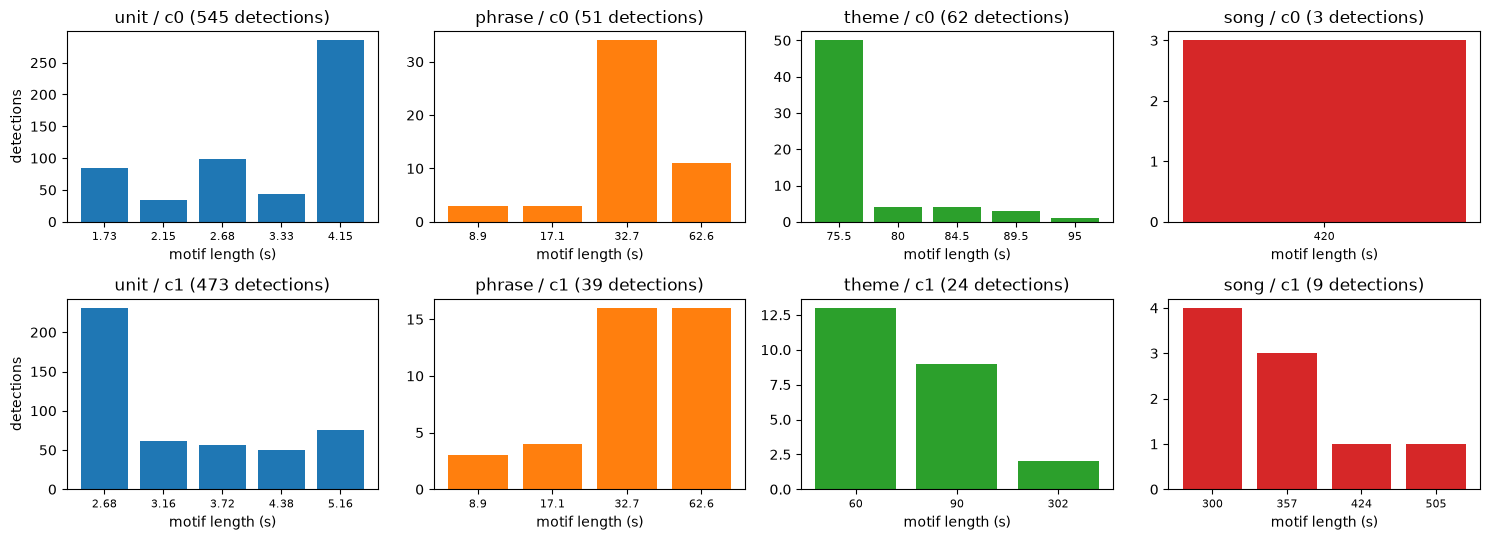

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(15, 5.5))
for i, feature in enumerate(FEATURES):
    for j, level in enumerate(LEVELS):
        ax = axes[i, j]
        det = ACC[(ACC.file == "10h") & (ACC.feature == feature) & (ACC.level == level)]
        counts = det["length_s"].round(2).value_counts().sort_index()
        ax.bar([f"{x:.3g}" for x in counts.index], counts.values, color=COLORS[level])
        ax.set_title(f"{level} / {feature} ({len(det)} detections)")
        ax.set_xlabel("motif length (s)")
        ax.tick_params(axis="x", labelsize=8)
axes[0, 0].set_ylabel("detections")
axes[1, 0].set_ylabel("detections")
fig.tight_layout()
plt.show()

## Timelines

One row per level. Each detection is drawn as two spans (its two occurrences) joined by an arc. The grey band marks
the 37.5-minute recording.

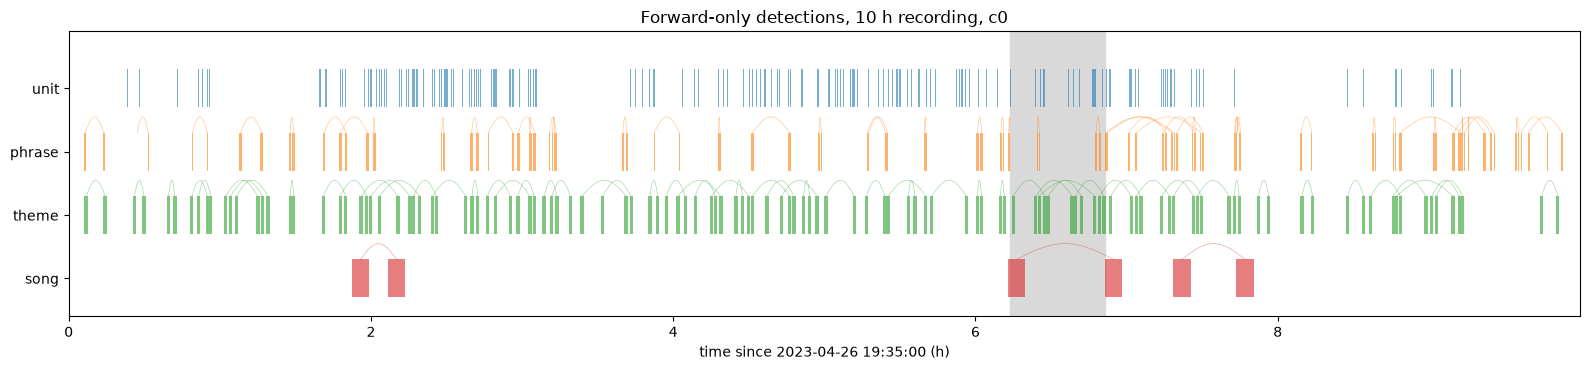

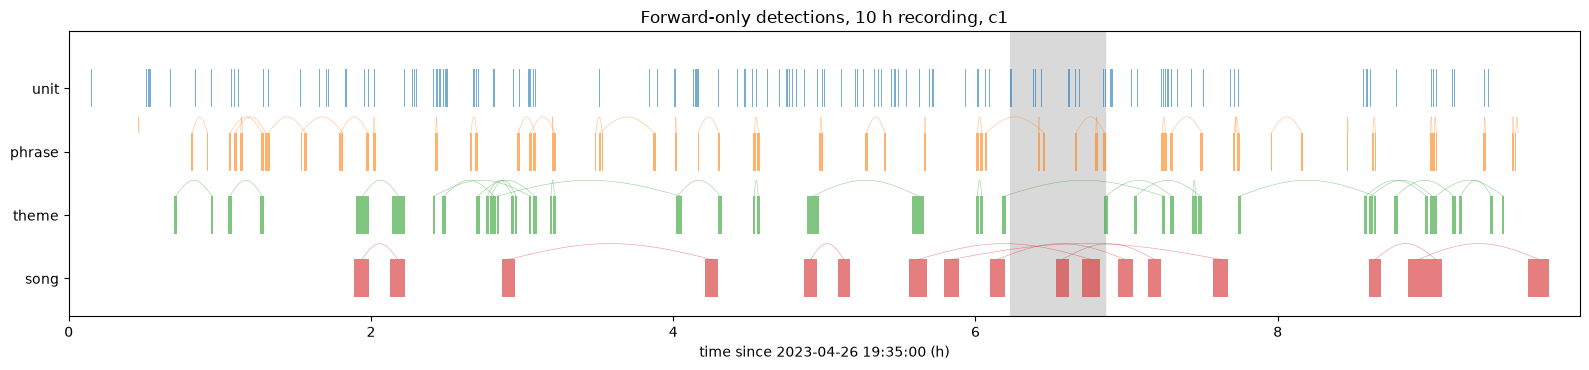

In [6]:
def draw_detections(ax, det, y, color, to_hours=True, arcs=True, offset_min=0.0):
    scale = 60.0 if to_hours else 1.0
    for _, d in det.iterrows():
        a = (d.start1_min + offset_min) / scale
        b = (d.start2_min + offset_min) / scale
        width = d.length_s / 60 / scale
        for x in (a, b):
            ax.add_patch(Rectangle((x, y - 0.3), width, 0.6, color=color, alpha=0.6, lw=0))
        if arcs:
            xs = np.linspace(a + width / 2, b + width / 2, 30)
            h = 0.25 * np.sin(np.linspace(0, np.pi, 30))
            ax.plot(xs, y + 0.3 + h, c=color, lw=0.4, alpha=0.5)


for feature in FEATURES:
    fig, ax = plt.subplots(figsize=(16, 3.8))
    ax.axvspan(OFFSET_MIN / 60, (OFFSET_MIN + DURATION_MIN["37min"]) / 60, color="0.85", zorder=0)
    for k, level in enumerate(LEVELS):
        det = ACC[(ACC.file == "10h") & (ACC.feature == feature) & (ACC.level == level)]
        draw_detections(ax, det, len(LEVELS) - 1 - k, COLORS[level], arcs=len(det) < 400)
    ax.set_yticks(range(len(LEVELS)))
    ax.set_yticklabels(LEVELS[::-1])
    ax.set_ylim(-0.6, len(LEVELS) - 0.1)
    ax.set_xlim(0, DURATION_MIN["10h"] / 60)
    ax.set_xlabel("time since 2023-04-26 19:35:00 (h)")
    ax.set_title(f"Forward-only detections, 10 h recording, {feature}")
    fig.tight_layout()
    plt.show()

### Zoom on the 37.5-minute recording: 10-hour search vs. independent search

For each level, the upper row shows the detections of the 10-hour search inside the overlap and the lower row the
detections of the separate search on the 37.5-minute file (shifted to the same clock).

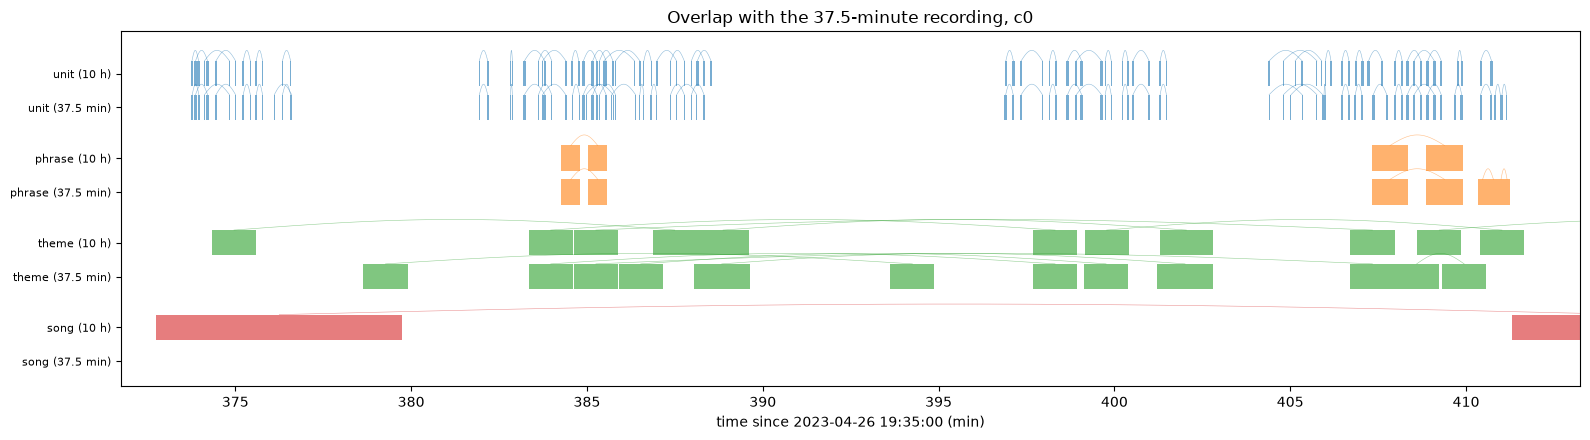

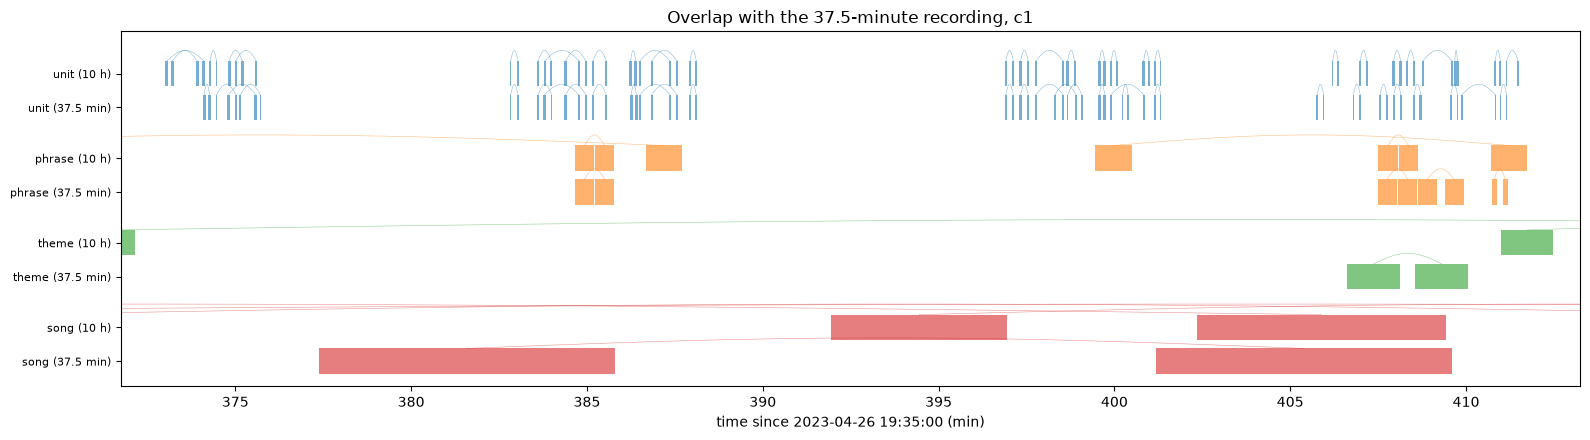

In [7]:
lo, hi = OFFSET_MIN, OFFSET_MIN + DURATION_MIN["37min"]
for feature in FEATURES:
    fig, ax = plt.subplots(figsize=(16, 4.5))
    ticks, labels = [], []
    for k, level in enumerate(LEVELS):
        y = 2 * (len(LEVELS) - 1 - k)
        d10 = ACC[(ACC.file == "10h") & (ACC.feature == feature) & (ACC.level == level)]
        d10 = d10[(d10.end2_min > lo) & (d10.start1_min < hi)]
        d37 = ACC[(ACC.file == "37min") & (ACC.feature == feature) & (ACC.level == level)]
        draw_detections(ax, d10, y + 0.8, COLORS[level], to_hours=False)
        draw_detections(ax, d37, y, COLORS[level], to_hours=False, offset_min=OFFSET_MIN)
        ticks += [y + 0.8, y]
        labels += [f"{level} (10 h)", f"{level} (37.5 min)"]
    ax.set_yticks(ticks)
    ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlim(lo - 2, hi + 2)
    ax.set_ylim(-0.6, 2 * len(LEVELS) - 0.2)
    ax.set_xlabel("time since 2023-04-26 19:35:00 (min)")
    ax.set_title(f"Overlap with the 37.5-minute recording, {feature}")
    fig.tight_layout()
    plt.show()

## Strongest detections

z-normalized overlays of the two occurrences of the three detections with the largest excess correlation per level
(10-hour search), plotted at the level's frame rate.

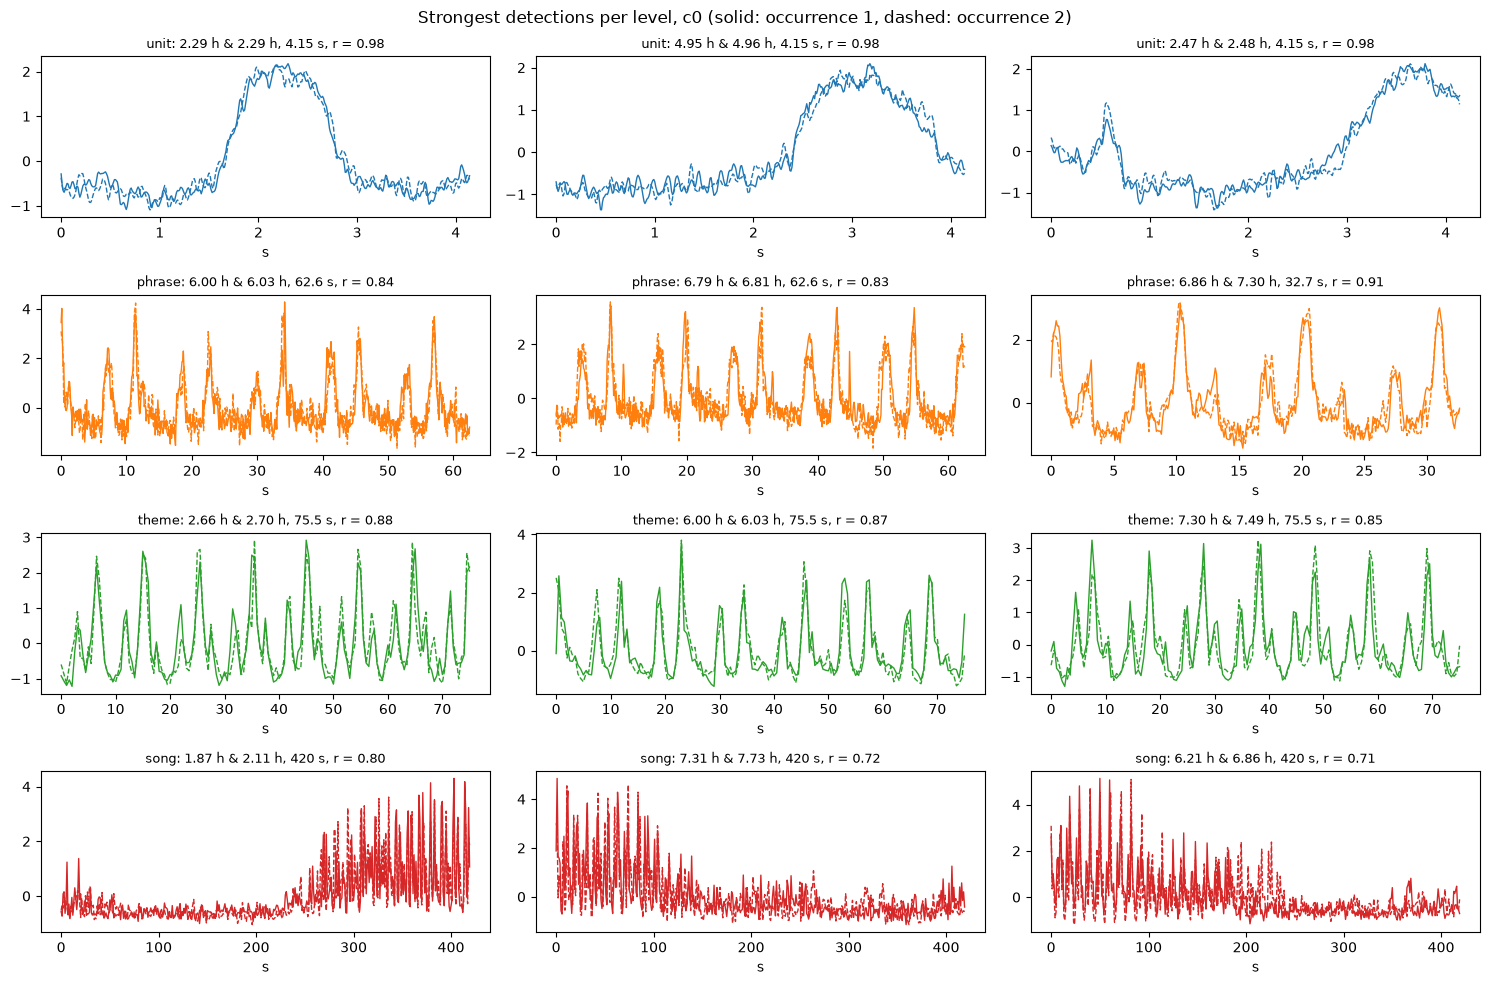

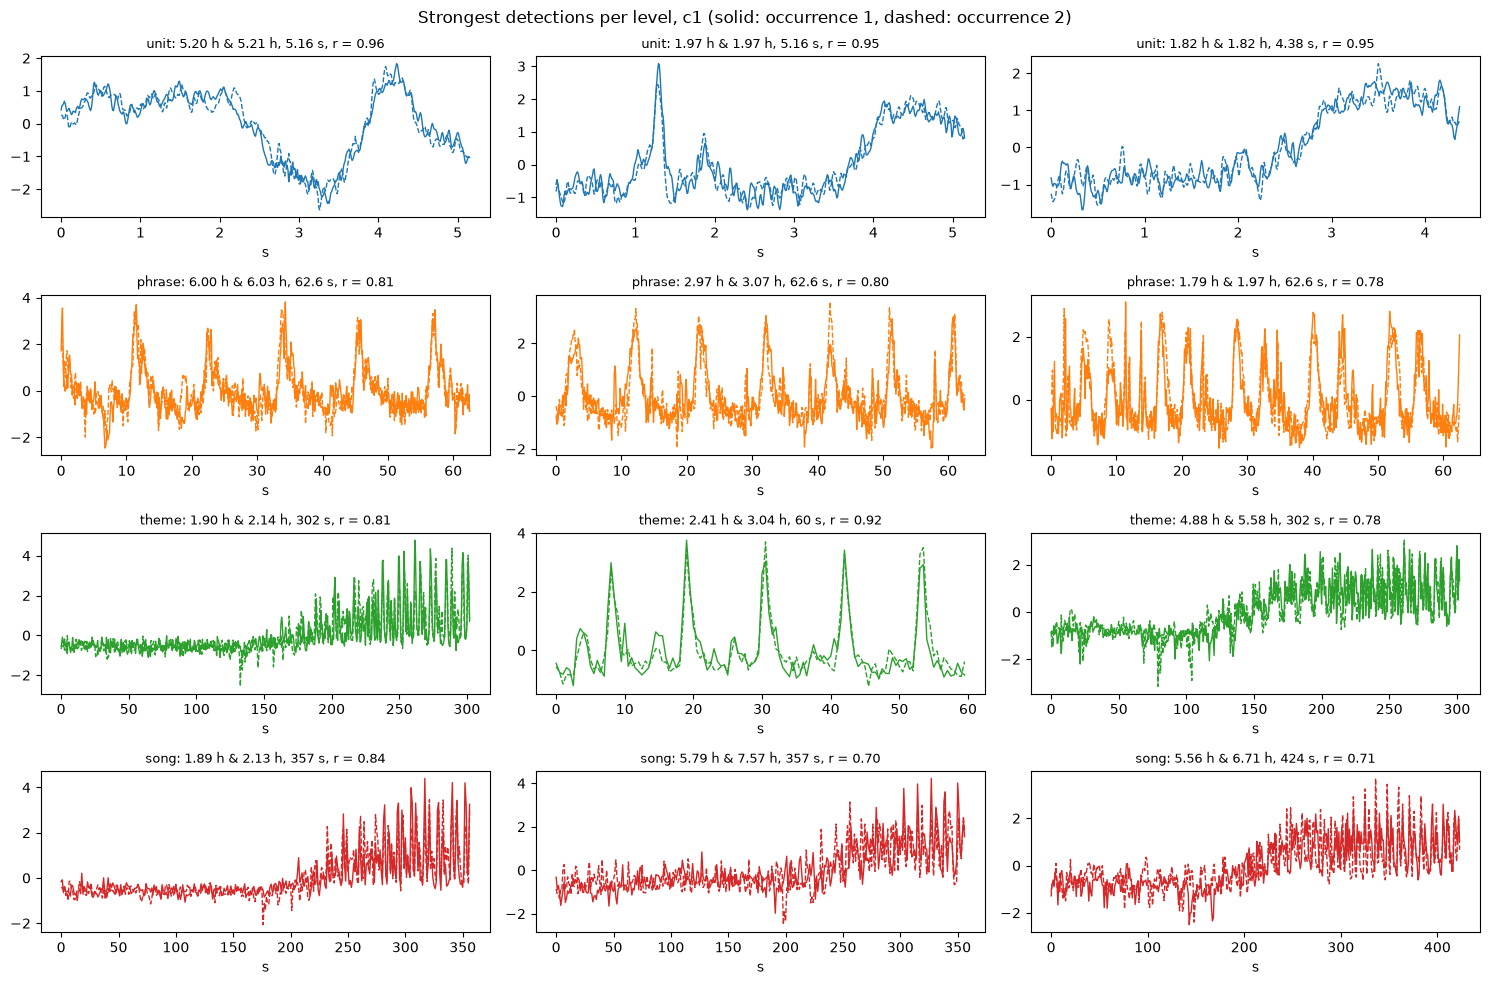

In [8]:
for feature in FEATURES:
    fig, axes = plt.subplots(len(LEVELS), 3, figsize=(15, 10))
    for k, level in enumerate(LEVELS):
        cfg = RANGES[feature][level]
        rate = cfg["rate_hz"]
        col = RANGES["meta"]["feature_columns"][feature]
        T = w.block_average(C10[:, col], int(round(FRAME_RATE / rate)))
        det = ACC[(ACC.file == "10h") & (ACC.feature == feature) & (ACC.level == level)]
        top = det.sort_values("score", ascending=False).head(3)
        for j in range(3):
            ax = axes[k, j]
            if j >= len(top):
                ax.axis("off")
                continue
            d = top.iloc[j]
            m = int(d.m)
            t = np.arange(m) / rate
            for start, ls in ((int(d.i), "-"), (int(d.j), "--")):
                x = T[start : start + m]
                ax.plot(t, (x - x.mean()) / x.std(), ls, c=COLORS[level], lw=1)
            ax.set_title(f"{level}: {d.start1_min / 60:.2f} h & {d.start2_min / 60:.2f} h, "
                         f"{d.length_s:.3g} s, r = {d.correlation:.2f}", fontsize=9)
            ax.set_xlabel("s")
    fig.suptitle(f"Strongest detections per level, {feature} (solid: occurrence 1, dashed: occurrence 2)")
    fig.tight_layout()
    plt.show()

## Correlation of accepted and rejected candidates

Excess over the null threshold at the candidate's length (0 = threshold). This shows how close the rejected
candidates were and where a different threshold would cut.

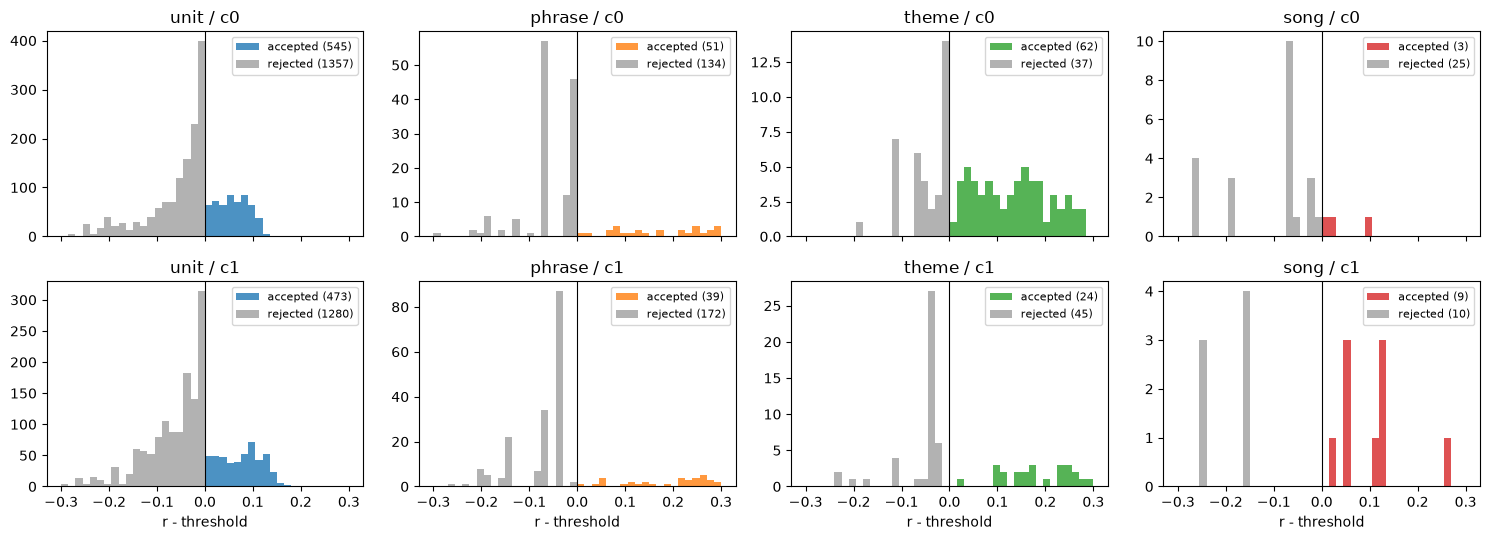

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(15, 5.5), sharex=True)
bins = np.linspace(-0.3, 0.3, 41)
for i, feature in enumerate(FEATURES):
    for j, level in enumerate(LEVELS):
        ax = axes[i, j]
        df = ALL[(ALL.file == "10h") & (ALL.feature == feature) & (ALL.level == level)].dropna(subset=["correlation"])
        ex = df["correlation"] - df["threshold"]
        acc = df["accepted"].astype(bool)
        ax.hist(ex[acc], bins=bins, color=COLORS[level], alpha=0.8, label=f"accepted ({acc.sum()})")
        ax.hist(ex[~acc], bins=bins, color="0.5", alpha=0.6, label=f"rejected ({(~acc).sum()})")
        ax.axvline(0, c="k", lw=0.8)
        ax.set_title(f"{level} / {feature}")
        ax.legend(fontsize=8)
for ax in axes[1]:
    ax.set_xlabel("r - threshold")
fig.tight_layout()
plt.show()

## Cross-check with the 37.5-minute recording

The two searches see almost the same data in the overlap (feature r > 0.99), but their windows are not aligned:
the 10-hour search arrives at the overlap with a lower bound set by earlier detections, and its windows can reach
outside the overlap. Exact agreement is therefore not expected. A 37.5-minute detection counts as **matched** if
both of its occurrences overlap occurrences of 10-hour detections of the same feature and level. As a baseline,
`10 h coverage` is the fraction of the overlap that lies inside 10-hour occurrences, which is roughly the chance
that a random occurrence would overlap one.

In [10]:
def overlaps_any(a, b, starts, ends):
    return bool(np.any((starts < b) & (ends > a)))


rows = []
for feature in FEATURES:
    for level in LEVELS:
        d10 = ACC[(ACC.file == "10h") & (ACC.feature == feature) & (ACC.level == level)]
        d37 = ACC[(ACC.file == "37min") & (ACC.feature == feature) & (ACC.level == level)]
        starts = np.r_[d10.start1_min, d10.start2_min]
        ends = np.r_[d10.end1_min, d10.end2_min]
        matched = [
            overlaps_any(d.start1_min + OFFSET_MIN, d.end1_min + OFFSET_MIN, starts, ends)
            and overlaps_any(d.start2_min + OFFSET_MIN, d.end2_min + OFFSET_MIN, starts, ends)
            for _, d in d37.iterrows()
        ]
        inside = d10[(d10.start1_min >= lo) & (d10.end2_min <= hi)]
        shifted = inside.assign(start1_min=inside.start1_min - OFFSET_MIN, end1_min=inside.end1_min - OFFSET_MIN,
                                start2_min=inside.start2_min - OFFSET_MIN, end2_min=inside.end2_min - OFFSET_MIN)
        rows.append({
            "feature": feature, "level": level, "37.5 min detections": len(d37),
            "10 h detections inside": len(inside),
            "matched": f"{np.mean(matched):.0%}" if matched else "-",
            "10 h coverage": f"{covered_fraction(shifted, DURATION_MIN['37min']):.0%}",
        })
pd.DataFrame(rows).set_index(["feature", "level"])

37.5 min detections  10 h detections inside matched 10 h coverage
feature level                                                                    
c0      unit                     48                      44     83%           13%
        phrase                    4                       2     50%            8%
        theme                     6                       4     83%           28%
        song                      0                       0       -            0%
c1      unit                     30                      27     73%            9%
        phrase                    4                       2     75%            6%
        theme                     1                       0      0%            0%
        song                      1                       0      0%            0%

## Export

All detections (both features, both recordings) with times on the 10-hour clock as well (`*_10h_min`).
Rejected candidates stay in the per-level caches `whale_forward_<level>_<feature>_<file>.csv`.

In [11]:
out = ACC[["file", "feature", "level", "iteration", "length_s", "start1_min", "start2_min", "correlation",
           "threshold", "score", "lb_min", "window_end_min"]].copy()
shift = np.where(out["file"] == "37min", OFFSET_MIN, 0.0)
out["start1_10h_min"] = out["start1_min"] + shift
out["start2_10h_min"] = out["start2_min"] + shift
out.to_csv("whale_forward_detections.csv", index=False)
print(f"wrote {len(out):,} detections to whale_forward_detections.csv")
out.groupby(["file", "feature", "level"]).size().unstack("level")[LEVELS]

wrote 1,300 detections to whale_forward_detections.csv


level           unit  phrase  theme  song
file  feature                            
10h   c0       545.0    51.0   62.0   3.0
      c1       473.0    39.0   24.0   9.0
37min c0        48.0     4.0    6.0   NaN
      c1        30.0     4.0    1.0   1.0

## Notes

- **Units (2–5 s)** are by far the most frequent detections: about 50 per hour per feature, matched with r ≈ 0.88–0.93
  (median). The two occurrences of a unit detection are typically **~13 s apart** (median 0.21–0.23 min). That is
  about one phrase period (~11 s in Phase 1), so a unit is usually matched with the same unit in the next phrase.
- **Phrase-band detections (9–120 s)** mostly pick 33–63 s motifs. Their overlays show a train of peaks every ~7–11 s
  repeated in both occurrences, i.e. several repetitions of the same phrase, which is the theme structure of the
  song. The theme level (c0: 75–95 s; c1: 60–300 s) finds the same kind of repeated-phrase sequences, with
  occurrences ~11–21 min apart (about one song cycle).
- **Song level.** Only 3 (c0) and 9 (c1) detections in 10 h. The strongest ones line up the *transition between
  silence and singing* (the start or end of a singing bout) rather than the song content, because z-normalized
  correlation over 5–10 min is dominated by that large loudness change. Song-level motifs need either removing the
  slow loudness trend first or comparing only stretches where the whale sings.
- **The forward rule leaves gaps.** After a detection the lower bound jumps to the end of the earlier occurrence,
  so everything between the old lower bound and that occurrence is never searched again. With long windows (theme:
  24–76 min, song: 2.3–2.5 h, capped at the file for the 37.5-minute run), each level yields only a few detections
  per window. `covered` in the summary shows how much of the night ends up inside a detection.
- **Cross-check.** Unit detections of the independent 37.5-minute search overlap 10-hour detections 73–83% of the
  time, against a 9–13% chance level, so they are reproducible. The longer levels have too few detections in
  37.5 minutes (the window is capped at the file, so the search starts from a different place) for a meaningful
  comparison.
- **Possible next steps:** group detections into templates (e.g. cluster the unit detections by shape), detrend
  the loudness before the song-level search, and try the search on c1 only within singing bouts.